# 03.2 · K-nearest neighbours by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/02-knn-by-hand/lesson.ipynb)

Read the [README](README.md) and do the distance table on paper first. Here you compute all 20 distances in NumPy, vote, change k, then see what scaling does, then run KNN on the real churn table.

## 1. The 20 customers and the newcomer

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


In [2]:
new = np.array([6, 30])          # C021: 6 visits, 30 days since last order

## 2. Distances, in NumPy

One line computes the README's table for all 20 customers: subtract, square, sum across the two features, square-root.

In [3]:
diff = X20.values - new                   # shape (20, 2): differences per feature
dist = np.sqrt((diff ** 2).sum(axis=1))   # shape (20,): one distance per customer

table = cust20[["customer_id", "visits_last_month", "days_since_last", "churned"]].copy()
table["distance"] = dist.round(2)
table.sort_values("distance").head(7)

,customer_id,visits_last_month,days_since_last,churned,distance
9,C010,2,28,1,4.47
4,C005,7,25,1,5.10
12,C013,11,28,0,5.39
15,C016,12,29,0,6.08
18,C019,12,34,1,7.21
2,C003,10,22,0,8.94
7,C008,10,22,0,8.94


Compare with your paper: C010 at 4.47, C005 at 5.10, C013 at 5.39, C016 at 6.08, C019 at 7.21.

## 3. Vote

In [4]:
for k in [1, 3, 5, 7]:
    nearest = table.sort_values("distance").head(k)
    churn_votes = nearest["churned"].sum()
    print(f"k={k}: neighbours {list(nearest['customer_id'])}, churn votes {churn_votes}/{k} "
          f"→ p̂ = {churn_votes / k:.2f} → predict {'CHURN' if churn_votes / k > 0.5 else 'stay'}")

k=1: neighbours ['C010'], churn votes 1/1 → p̂ = 1.00 → predict CHURN
k=3: neighbours ['C010', 'C005', 'C013'], churn votes 2/3 → p̂ = 0.67 → predict CHURN
k=5: neighbours ['C010', 'C005', 'C013', 'C016', 'C019'], churn votes 3/5 → p̂ = 0.60 → predict CHURN
k=7: neighbours ['C010', 'C005', 'C013', 'C016', 'C019', 'C003', 'C008'], churn votes 3/7 → p̂ = 0.43 → predict stay


The prediction flips between k = 5 and k = 7. C021 sits near the boundary, and k decides how far out we look.

## 4. scikit-learn does the same thing

In [5]:
from sklearn.neighbors import KNeighborsClassifier

knn5 = KNeighborsClassifier(n_neighbors=5).fit(X20, y20)
new_df = pd.DataFrame([new], columns=X20.columns)
print("predict:", knn5.predict(new_df), " predict_proba [stay, churn]:", knn5.predict_proba(new_df))

# which rows did it use?  kneighbors returns distances and row positions
d, idx = knn5.kneighbors(new_df)
print("distances:", d.round(2), "\ncustomers:", list(cust20.loc[idx[0], "customer_id"]))

predict: [1]  predict_proba [stay, churn]: [[0.4 0.6]]
distances: [[4.47 5.1  5.39 6.08 7.21]] 
customers: ['C010', 'C005', 'C013', 'C016', 'C019']


## 5. k shapes the boundary

Small k follows every local quirk; large k smooths. Watch the map change.

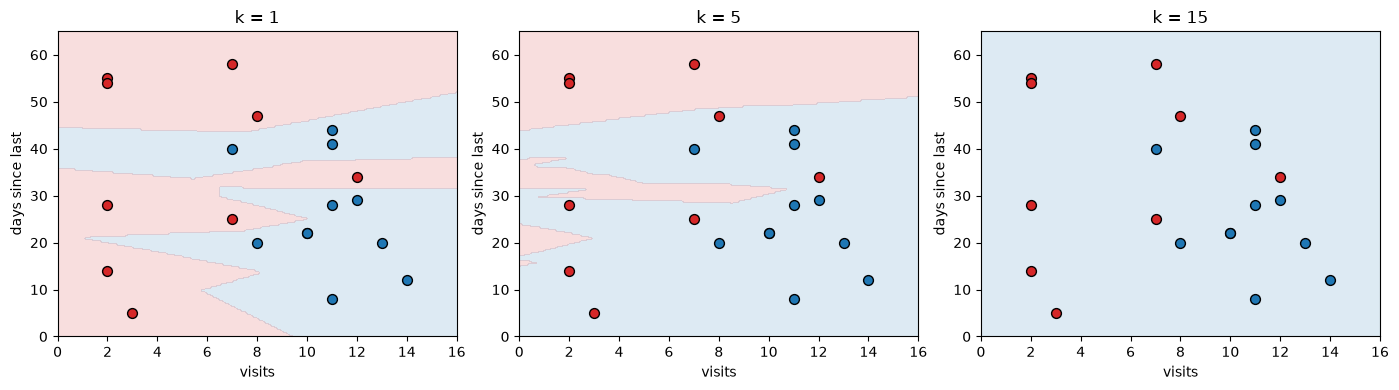

In [6]:
def plot_boundary(model, ax, title):
    vv, dd = np.meshgrid(np.linspace(0, 16, 200), np.linspace(0, 65, 200))
    grid = pd.DataFrame({"visits_last_month": vv.ravel(), "days_since_last": dd.ravel()})
    zz = model.predict(grid).reshape(vv.shape)
    ax.contourf(vv, dd, zz, levels=[-0.5, 0.5, 1.5], colors=["tab:blue", "tab:red"], alpha=.15)
    for label, colour in [(0, "tab:blue"), (1, "tab:red")]:
        sub = cust20[cust20["churned"] == label]
        ax.scatter(sub["visits_last_month"], sub["days_since_last"], c=colour, s=50, edgecolor="k")
    ax.set_title(title); ax.set_xlabel("visits"); ax.set_ylabel("days since last")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axes, [1, 5, 15]):
    plot_boundary(KNeighborsClassifier(n_neighbors=k).fit(X20, y20), ax, f"k = {k}")
plt.tight_layout(); plt.show()

## 6. The scaling trap

`days_since_last` runs 5–58, `visits_last_month` 2–14. Unscaled, the distance is mostly about days. Standardise both (subtract mean, divide by std) and recompute.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X20)
print("means:", scaler.mean_.round(2), " stds:", scaler.scale_.round(2))

X20_s = scaler.transform(X20)
new_s = scaler.transform(new_df)
print("C021 scaled:", new_s.round(2))

dist_s = np.sqrt(((X20_s - new_s) ** 2).sum(axis=1))
table["distance_scaled"] = dist_s.round(2)
table.sort_values("distance_scaled").head(5)

means: [ 8.15 30.3 ]  stds: [ 3.93 15.42]
C021 scaled: [[-0.55 -0.02]]


,customer_id,visits_last_month,days_since_last,churned,distance,distance_scaled
4,C005,7,25,1,5.10,0.41
19,C020,7,40,0,10.05,0.70
16,C017,8,20,0,10.20,0.82
9,C010,2,28,1,4.47,1.03
2,C003,10,22,0,8.94,1.14


In [8]:
nearest_s = table.sort_values("distance_scaled").head(5)
print(f"scaled, k=5: churn votes {nearest_s['churned'].sum()}/5 → predict "
      f"{'CHURN' if nearest_s['churned'].mean() > 0.5 else 'stay'}")

scaled, k=5: churn votes 2/5 → predict stay


Same customers, same k, **opposite answer**. Three of the five unscaled neighbours were chosen mainly because their `days_since_last` was close to 30; after scaling, visits count equally and the neighbourhood changes.

From now on, every distance-based model gets a scaler in front of it. A `Pipeline` makes that impossible to forget:

In [9]:
from sklearn.pipeline import make_pipeline

knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X20, y20)
print("scaled pipeline predicts:", knn_scaled.predict(new_df), knn_scaled.predict_proba(new_df))

scaled pipeline predicts: [0] [[0.6 0.4]]


## 7. The real data

Five features, about 3,300 customers, a quarter held out as test customers.

In [10]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


> **About `train_test_split`.** We hold back 25% of customers and score the model only on those, because scoring a model on the rows it learned from is like marking your own homework. Module 04 explains this properly; for now, just know that `X_test` / `y_test` are "exam" customers the model never saw.

In [11]:
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"baseline: {baseline:.1%}\n")
print(f"{'k':>4} {'unscaled':>10} {'scaled':>10}")
for k in [1, 5, 15, 51]:
    raw_acc = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_test, y_test)
    sc_acc = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train).score(X_test, y_test)
    print(f"{k:>4} {raw_acc:>10.1%} {sc_acc:>10.1%}")

baseline: 56.4%

   k   unscaled     scaled
   1      60.6%      58.3%
   5      62.0%      61.4%
  15      66.0%      64.5%
  51      67.7%      67.8%


Accuracy rises with k as the jagged small-k boundary gets smoothed. Scaling makes little difference *here*, which is itself informative: the exercises ask you to find out why (one feature dominates the distances both ways).

## Quiz answers

1. Nothing but store the training table. All the work happens at prediction time.
2. $\sqrt{(3-0)^2 + (4-0)^2} = \sqrt{9 + 16} = 5$.
3. $\hat{p} = 3/5 = 0.6$, $\hat{y} = 1$ (churn).
4. KNN compares *distances*, which add up differences across features, so a feature with bigger numbers dominates. A tree compares one feature with a threshold at a time; multiplying a feature by 100 just multiplies the threshold by 100.
5. Small k: captures fine local structure. Large k: smooths noise and is more stable. Choose by testing.

**Next:** [03.3 Decision tree classifier](../03-decision-tree-classifier/)